<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/01_tabular/05_clustering_app_customer_segments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧺 Application · Unsupervised learning: Who are our customers? (clustering)

So far every dataset came with an answer column. Real life is often less generous: a wholesaler in Lisbon knows what
each of its 440 clients bought last year (fresh food, milk, groceries, frozen, detergents, delicatessen)… but nobody
ever wrote down *what kind of business* each client is.

**Clustering** finds groups of similar rows **without labels**. It is **unsupervised learning**. Marketing teams use it
to design offers per segment, banks to profile customers, biologists to group genes, astronomers to classify galaxies.

The idea is old: Hugo Steinhaus described the **k-means** principle in **1956**, Stuart Lloyd wrote the algorithm we
still use at Bell Labs in 1957 (published only in 1982). Density-based **DBSCAN** arrived in 1996.

**Mission:** discover customer segments, describe them as *personas*, and check them against a hidden truth.

| You will learn | Concept |
|---|---|
| Why scaling and log transforms matter for distances | preprocessing for unsupervised learning |
| k-means, how to choose *k* | inertia (elbow), silhouette |
| Seeing 6 dimensions in 2 | PCA |
| Other algorithms | hierarchical clustering, DBSCAN, Gaussian mixtures |
| Turning clusters into business | personas |

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

quest("Who are our customers?", chapter="Track 1 · Tabular · Clustering (bonus)", xp=200)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Who are our customers?
   Track 1 · Tabular · Clustering (bonus)
   Reward: up to 200 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load 📥
UCI's *Wholesale customers* dataset (Margarida Cardoso, 2014): annual spending in monetary units per product family.
It also contains `Channel` (1 = Hotel/Restaurant/Café, "Horeca"; 2 = Retail) and `Region`. We **hide** `Channel` and
use it only at the end to see whether our clusters rediscovered it.

In [3]:
folder = download_and_extract("https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip",
                              "wholesale", marker="Wholesale customers data.csv")
raw = pd.read_csv(folder / "Wholesale customers data.csv")
channel = raw.pop("Channel").map({1: "Horeca", 2: "Retail"})
region = raw.pop("Region")
X = raw
X.describe().round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


## 2. Distances need care 📏

k-means groups points that are **close**. Two problems with raw spending:
1. **Skewness**: a few clients spend 50× the median. They dominate every distance.
2. **Scale**: `Fresh` is in the tens of thousands, `Delicassen` in the hundreds.

Fix: take the **log** (spending ratios matter more than amounts) and **standardise** each column.

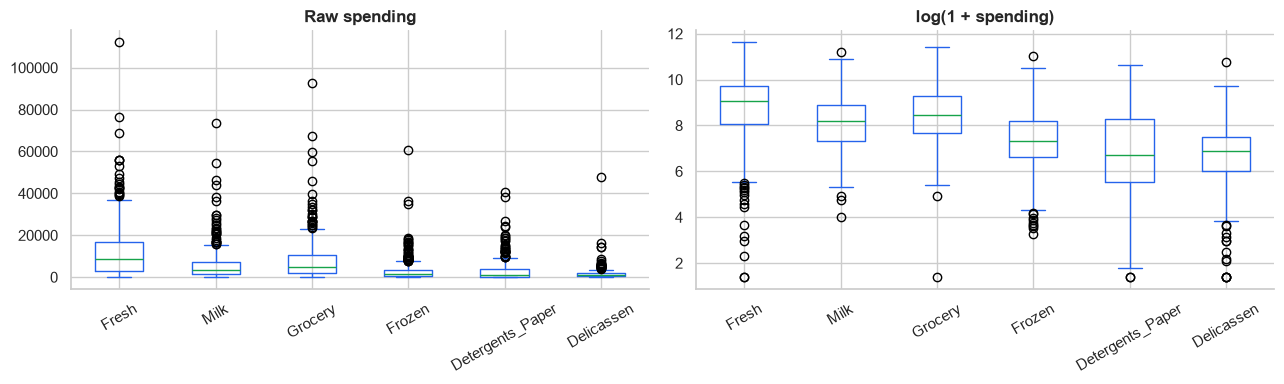

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
X.plot.box(ax=axes[0], title="Raw spending", rot=30)
X_log = np.log1p(X)
X_log.plot.box(ax=axes[1], title="log(1 + spending)", rot=30)
plt.tight_layout(); plt.show()

from sklearn.preprocessing import StandardScaler
Z = StandardScaler().fit_transform(X_log)

## 3. k-means and the choice of *k* 🔢

k-means alternates two steps until nothing moves: (1) assign each point to the nearest centre, (2) move each centre to
the mean of its points. But how many clusters? Two classic tools:
- **Inertia** (sum of squared distances to the centres): always decreases with *k*; look for the "elbow".
- **Silhouette** (Rousseeuw, 1987): for each point, how much closer it is to its own cluster than to the next one
  (from −1 to 1, higher is better).

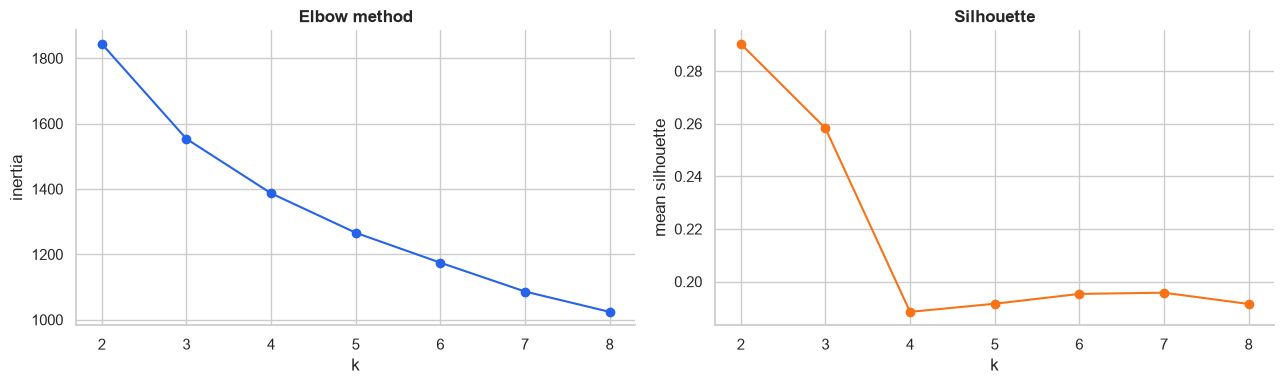

Best silhouette at k = 2


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 9)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertias, "o-"); axes[0].set(title="Elbow method", xlabel="k", ylabel="inertia")
axes[1].plot(ks, silhouettes, "o-", color="#f97316"); axes[1].set(title="Silhouette", xlabel="k", ylabel="mean silhouette")
plt.tight_layout(); plt.show()
best_k = list(ks)[int(np.argmax(silhouettes))]
print(f"Best silhouette at k = {best_k}")

There is rarely a single "right" *k*: the metrics give a range, and the **business** decides (how many different
offers can the marketing team handle?). Let's use the silhouette's choice.

In [6]:
km = KMeans(n_clusters=best_k, n_init=20, random_state=SEED).fit(Z)
labels = km.labels_
pd.Series(labels).value_counts().sort_index().rename("customers per cluster")

0    252
1    188
Name: customers per cluster, dtype: int64

In [7]:
checkpoint("clustering/kmeans", xp=40)

✅ Checkpoint · clustering/kmeans (+40 XP)
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 4. Seeing the clusters: PCA 👀

We have 6 dimensions; screens have 2. **Principal Component Analysis** (Pearson 1901, Hotelling 1933) finds the
directions along which the data varies most, and projects the points onto them.

The 2 components keep 71% of the variance


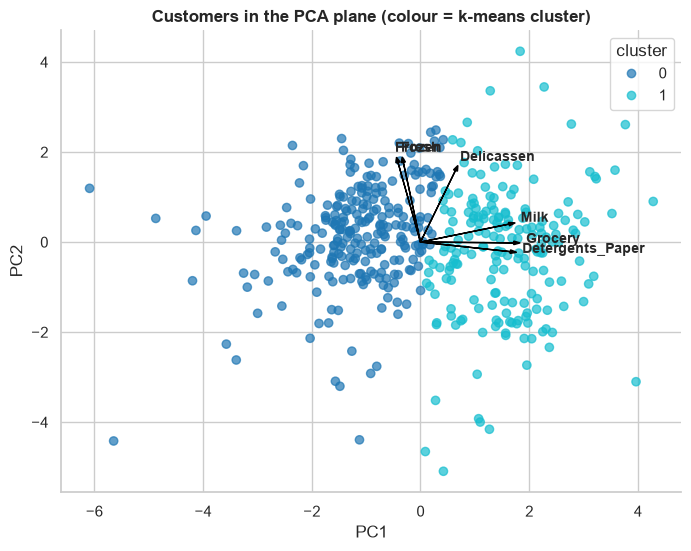

In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z)
print(f"The 2 components keep {pca.explained_variance_ratio_.sum():.0%} of the variance")
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(P[:, 0], P[:, 1], c=labels, cmap="tab10", alpha=0.7)
for j, col in enumerate(X.columns):          # arrows: how each original feature points in the PCA plane
    ax.arrow(0, 0, pca.components_[0, j] * 3, pca.components_[1, j] * 3, color="k", head_width=0.08)
    ax.text(pca.components_[0, j] * 3.4, pca.components_[1, j] * 3.4, col, fontsize=10, fontweight="bold")
ax.set(xlabel="PC1", ylabel="PC2", title="Customers in the PCA plane (colour = k-means cluster)")
ax.legend(*sc.legend_elements(), title="cluster"); plt.show()

## 5. From clusters to personas 🧑‍🍳🛒

A cluster is only useful once you can **name** it. Compare the median spending of each cluster with the overall
median (ratio > 1 = spends more than a typical customer).

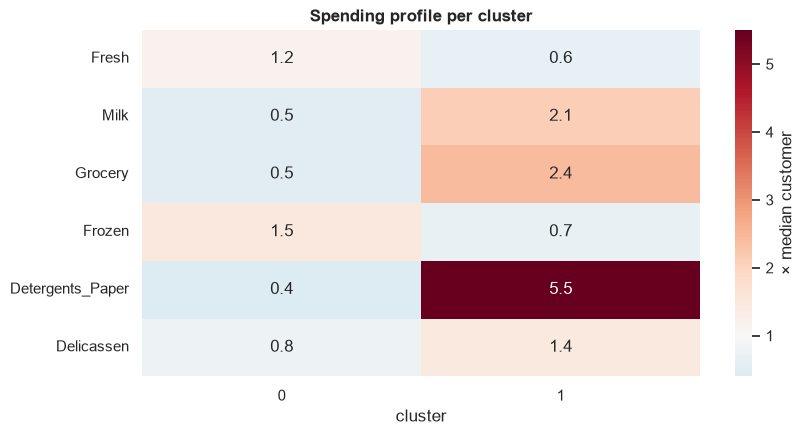

In [9]:
profile = X.groupby(labels).median() / X.median()
ax = sns.heatmap(profile.T, annot=True, fmt=".1f", cmap="RdBu_r", center=1, cbar_kws={"label": "× median customer"})
ax.set(xlabel="cluster", title="Spending profile per cluster"); plt.show()

Read the heatmap like a marketer: one group over-spends on **Fresh** and **Frozen** but buys little **Grocery** and
**Detergents_Paper** (restaurants and cafés cook fresh food), another buys **Grocery, Milk, Detergents** (shops
reselling packaged goods). With more clusters you'd also see "big accounts" and "small occasional buyers".

## 6. The moment of truth: did we rediscover the channel? 🔓

In [10]:
from sklearn.metrics import adjusted_rand_score

ct = pd.crosstab(pd.Series(labels, name="cluster"), channel)
print(ct)
print(f"\nAdjusted Rand Index vs Channel: {adjusted_rand_score(channel, labels):.2f}  (0 = random, 1 = identical)")

Channel  Horeca  Retail
cluster                
0           244       8
1            54     134

Adjusted Rand Index vs Channel: 0.51  (0 = random, 1 = identical)


Without ever seeing the `Channel` column, the clusters largely recover the Horeca / Retail split. That is the power
(and the purpose) of unsupervised learning: structure is already in the data.

## 7. Other algorithms, other shapes 🧪

k-means assumes round, similar-sized clusters. Alternatives:
- **Agglomerative (hierarchical) clustering**: merges the closest groups step by step; the *dendrogram* shows the
  whole hierarchy.
- **Gaussian Mixture Models**: soft clusters (each point gets probabilities), elliptical shapes.
- **DBSCAN**: groups dense regions and labels isolated points as **noise** (`-1`): handy to find unusual customers.

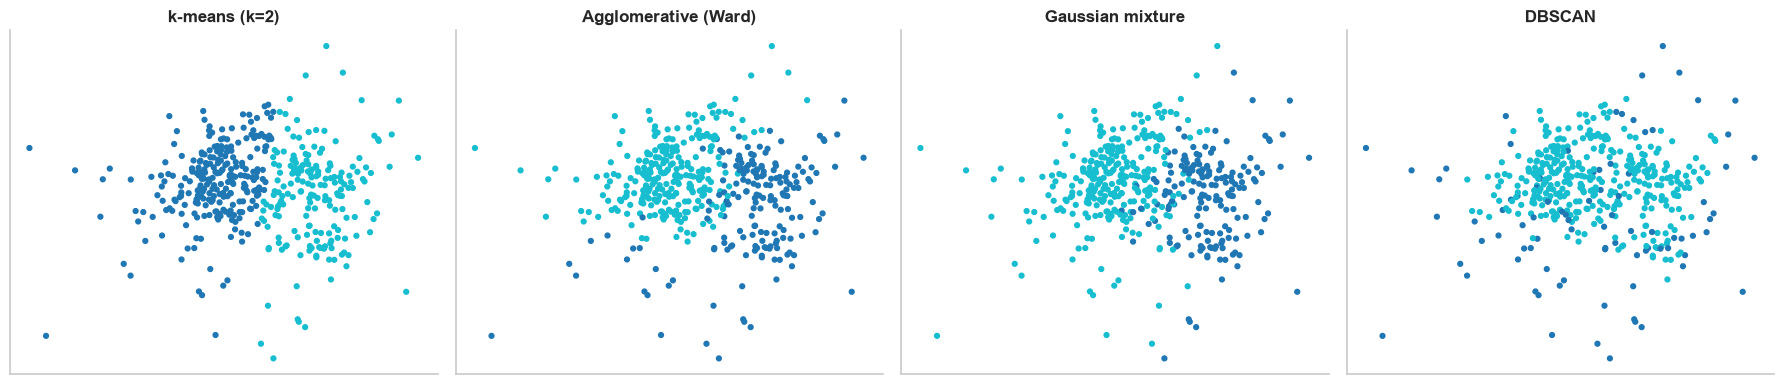

,algorithm,clusters,noise points,ARI vs Channel
0,k-means (k=2),2,0,0.51
1,Agglomerative (Ward),2,0,0.54
2,Gaussian mixture,2,0,0.62
3,DBSCAN,1,85,-0.01


In [11]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture

algos = {
    f"k-means (k={best_k})": labels,
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(Z),
    "Gaussian mixture": GaussianMixture(n_components=best_k, random_state=SEED, n_init=5).fit(Z).predict(Z),
    "DBSCAN": DBSCAN(eps=1.2, min_samples=8).fit_predict(Z),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
rows = []
for ax, (name, lab) in zip(axes, algos.items()):
    ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="tab10", s=12)
    ax.set(title=name, xticks=[], yticks=[])
    rows.append({"algorithm": name, "clusters": len(set(lab) - {-1}), "noise points": int((lab == -1).sum()),
                 "ARI vs Channel": round(adjusted_rand_score(channel, lab), 2)})
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

Here the **Gaussian mixture** recovers the channel best: its elliptical, soft clusters fit this data better than
k-means' round ones. **DBSCAN** finds a single dense core plus a few dozen **noise points** (`-1`). It is the wrong tool
to split these customers, but the right one to flag the customers that look like no one else, worth a look by a
salesperson (very large accounts, or data errors). Every algorithm answers a slightly different question.

## 🏁 Mission accomplished

You preprocessed data for distances, chose *k*, visualised with PCA, built personas and validated them against hidden
labels.

### 🚀 Your turn
1. Redo the analysis **without** the log transform. What happens to the clusters? Why?
2. Try `k = 4`, 5: can you name every persona?
3. Plot the dendrogram with `scipy.cluster.hierarchy.dendrogram` (use `linkage(Z, "ward")`).
4. Use clustering as a **feature** for a supervised model: add the cluster id (or distances to the centres) to a
   tabular competition dataset.

In [12]:
checkpoint("clustering/complete", xp=160)
badge("Segment Seeker", "🧺")
progress()

✅ Checkpoint · clustering/complete (+160 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ████████████░░░░░░░░░░░░ 200/300 XP
╔═══════════════════════════════════╗
║ 🧺  BADGE UNLOCKED: Segment Seeker ║
╚═══════════════════════════════════╝
🐣 Data Explorer
████████████░░░░░░░░░░░░ 200/300 XP
Checkpoints unlocked: 2
Badges: 🧺 Segment Seeker
